# Polychromatic diffraction with a spatially incoherent source

This examples illustrates the use of polychromatic extended sources. A Bahtinov mask produces diffraction spikes whose positions depend on wavelength. In the notebook, we first calculate the pattern under a narrow illumination cone and then we broaden that cone while keeping the incident spectrum fixed.

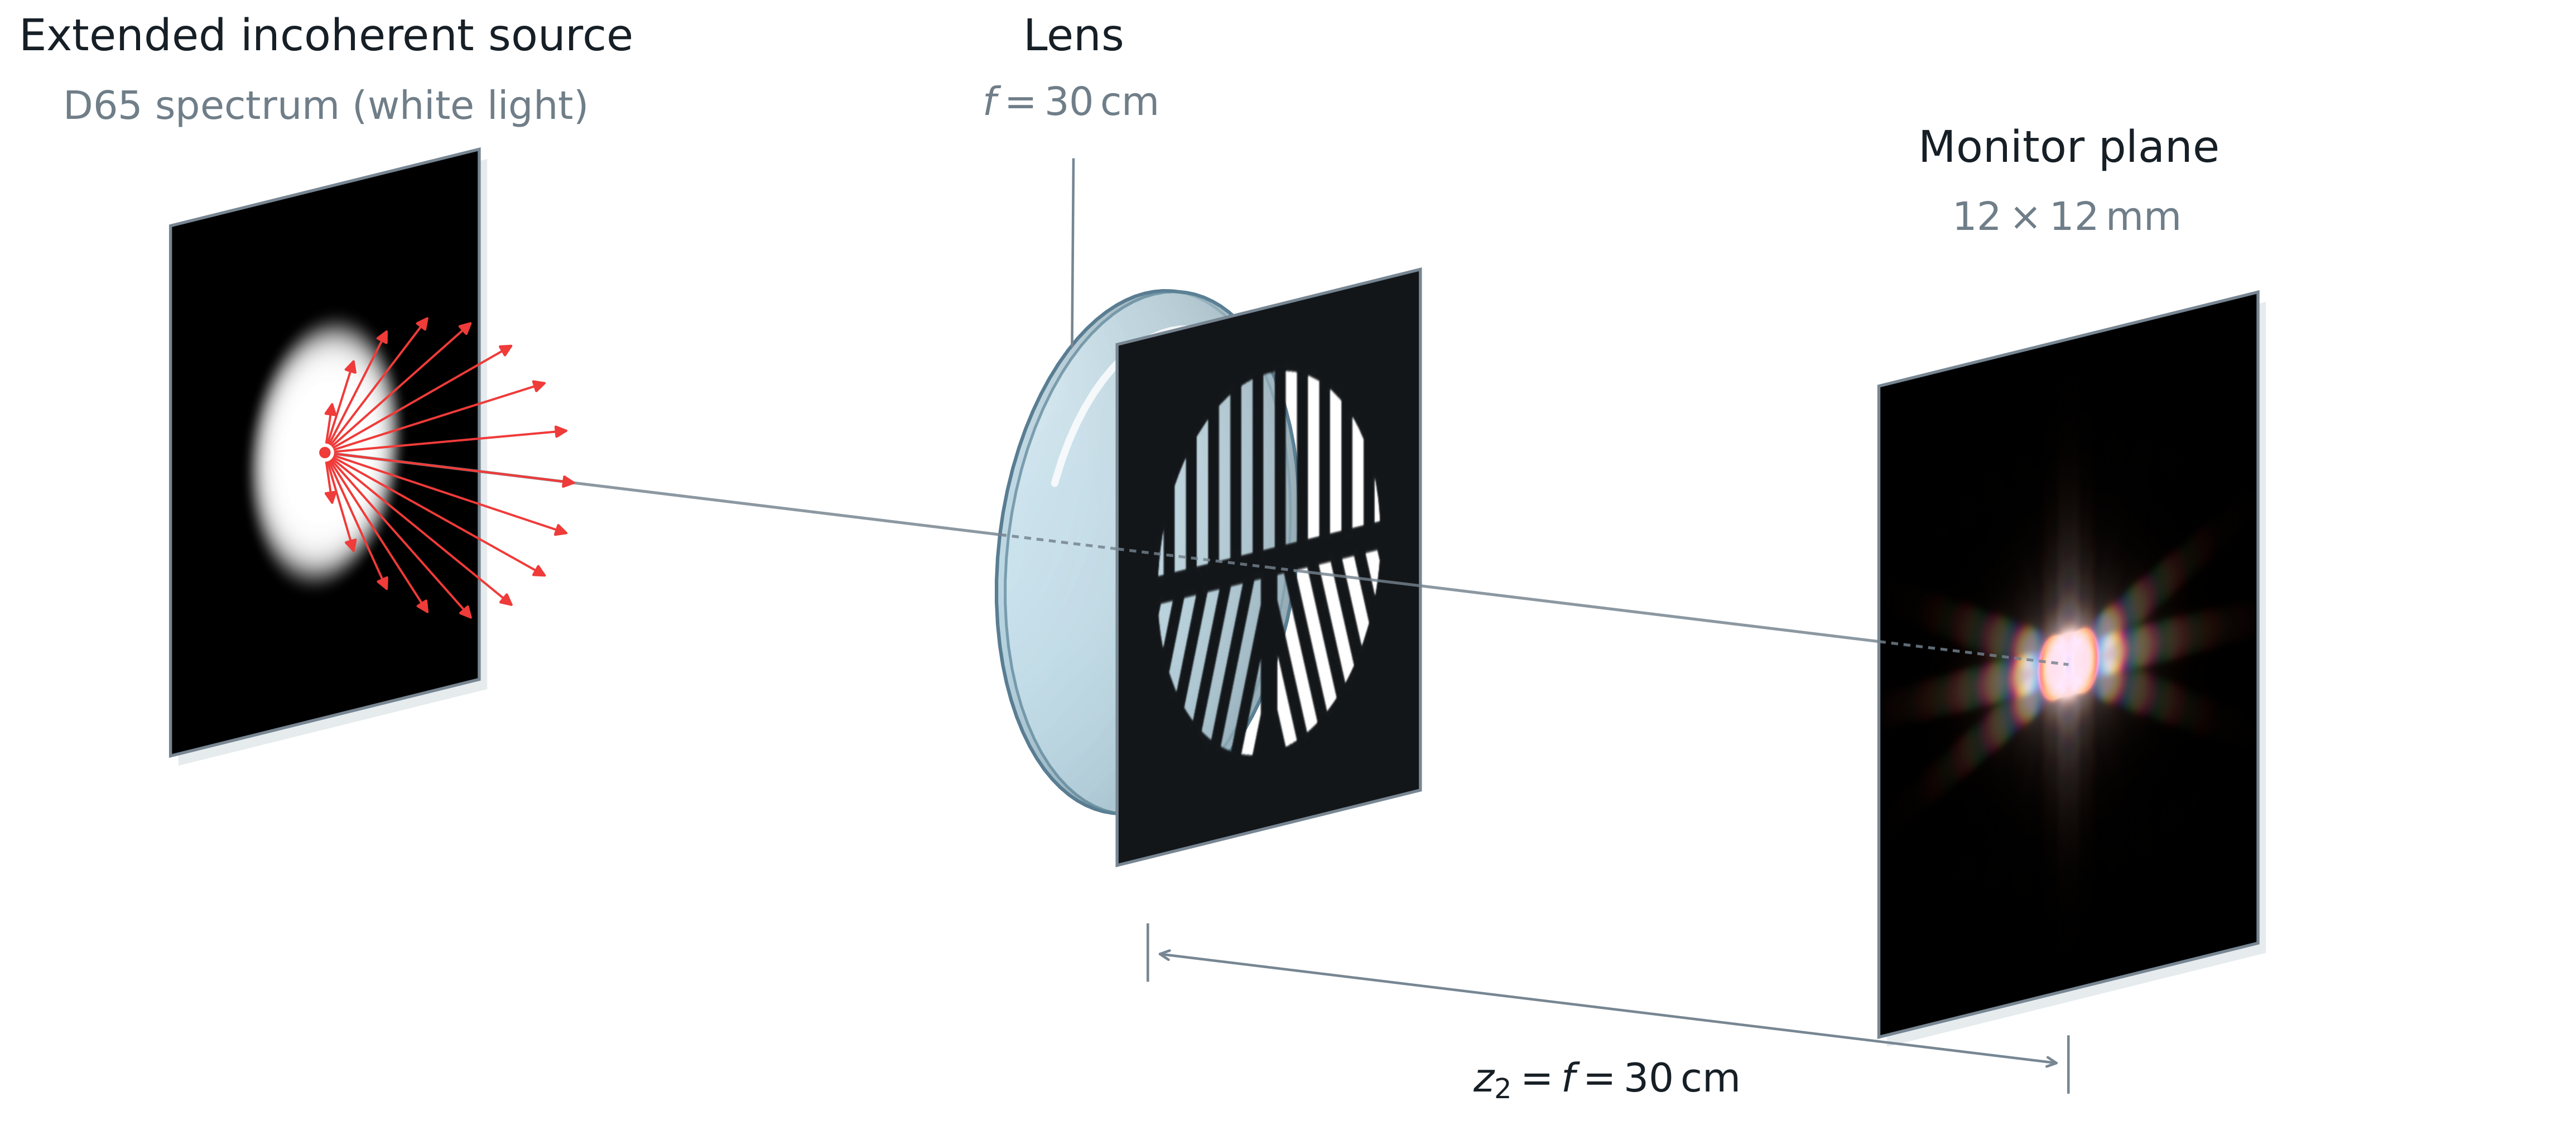

## 1. Illuminate the Bahtinov mask with a D65 spectrum (white light)

We use the same angular profile at every wavelength, writing the spectral radiance as $L_{\mathrm{in},\lambda}(\alpha',\beta')=E_{\mathrm{in},\lambda}\,g_{\theta_c}(\alpha',\beta')$. Here $E_{\mathrm{in},\lambda}$ is the incident spectral irradiance supplied by `spectrum`, and

$$
g_{\theta_c}(\alpha',\beta')=
\frac{2^{1/n}}{\pi s^2\Gamma(1+1/n)}
\exp\!\left[-2\left(\frac{\alpha'^2+\beta'^2}{s^2}\right)^n\right],
\qquad s=\sin\theta_c.
$$

The angular integral of $g_{\theta_c}$ is one, so changing $\theta_c$ preserves the incident spectral irradiance. At the cone half-angle $\theta_c$, the radiance is $e^{-2}$ of its central value. We choose $n=5$ for a nearly uniform cone with a smooth edge.

The response is:

$$
E_\lambda(x,y)\simeq\iint
L_{\mathrm{in},\lambda}(\alpha',\beta')\,
H^{\mathrm{mon}}_\lambda(x+f\alpha',y+f\beta')\,
\mathrm d\alpha'\,\mathrm d\beta'.
$$

$H^{\mathrm{mon}}_\lambda$ is the coherent focal-plane response for unit incident irradiance. `get_colors()` evaluates one such response per wavelength sample and also combines the spectral contributions with the colour-matching functions, and returns an sRGB image.

100% |#################################################################################################################|


Computation Took 2.286405086517334


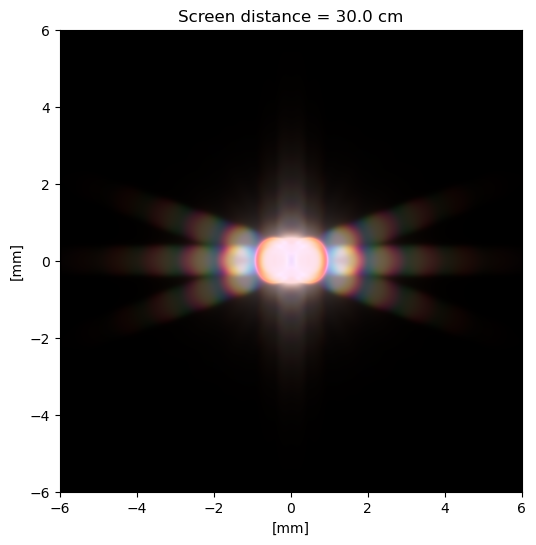

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from math import gamma
import diffractsim

diffractsim.set_backend("JAX")  # Change to "CUDA" for the CuPy backend.

import jax
jax.config.update("jax_enable_x64", True)

from diffractsim import PolychromaticSimulator, Lens, ApertureFromImage, cf, mm, cm
from diffractsim.util.backend_functions import backend as bd


# Super-Gaussian order: n=1 is Gaussian; larger n approaches a uniform cone.
n = 5
cone_half_angle = np.deg2rad(0.08)  # Radiance falls to 1/e² at this half-angle.

def illumination_cone(alpha, beta, half_angle=cone_half_angle):
    """Super-Gaussian radiance with unit integral over direction cosines."""
    s = bd.sin(half_angle)
    normalization = 2**(1 / n) / (bd.pi * s**2 * gamma(1 + 1 / n))
    radius_squared = (alpha**2 + beta**2) / s**2
    return normalization * bd.exp(-2 * radius_squared**n)


def optical_setup(F):
    F = F.add(ApertureFromImage(
        "./bahtinov_mask.jpg",
        image_size=(5 * mm, 5 * mm),
        simulation=F,
    ))
    F = F.add(Lens(f=30 * cm))
    F = F.propagate(z=30 * cm)
    return F


sim = PolychromaticSimulator(
    spectrum=4 * cf.illuminant_d65,
    extent_x=15 * mm,
    extent_y=15 * mm,
    Nx=1500,
    Ny=1500,
    optical_setup=optical_setup,
)
sim.set_angular_illumination(illumination_cone, paraxial=True)

rgb = sim.get_colors()
sim.plot_colors(rgb, xlim=[-6 * mm, 6 * mm], ylim=[-6 * mm, 6 * mm])

## 2. Broaden the source (cone_half_angle) and watch the colours blend and interferences dissapear

We now use half-angles of $0.01^\circ$, $0.1^\circ$ and $0.4^\circ$. 


100% |#################################################################################################################|


Computation Took 2.2811789512634277


100% |#################################################################################################################|


Computation Took 2.250204086303711


100% |#################################################################################################################|


Computation Took 2.26645827293396


100% |#################################################################################################################|


Computation Took 2.261453151702881


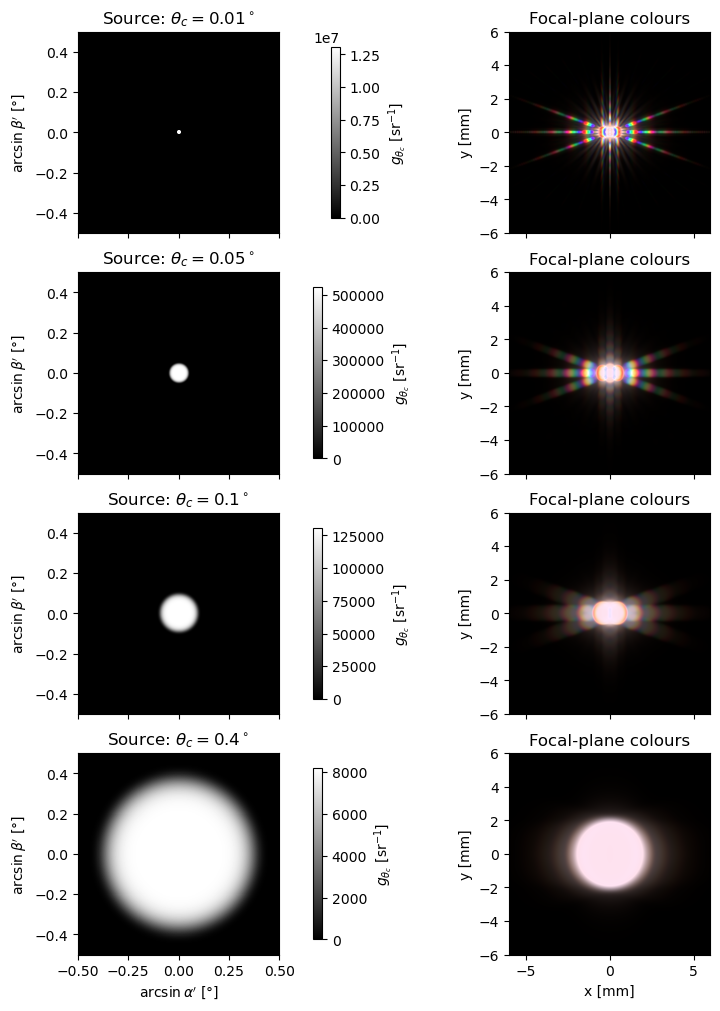

In [6]:
# 2. The same Bahtinov setup under three illumination half-angles.
half_angles = [0.01, 0.05, 0.1, 0.4]  # Degrees.
source_span = 1.25 * max(half_angles)
angles = bd.deg2rad(bd.linspace(-source_span, source_span, 601))
alpha, beta = bd.meshgrid(bd.sin(angles), bd.sin(angles))

def to_numpy(array):
    """Move plotted arrays from JAX or CuPy to NumPy."""
    return array.get() if hasattr(array, "get") else np.asarray(array)

fig, axes = plt.subplots(4, 2, figsize=(9, 10), layout="constrained",
                         sharex="col", sharey="col")
for row, half_angle in enumerate(half_angles):
    def source(alpha, beta, angle=np.deg2rad(half_angle)):
        return illumination_cone(alpha, beta, half_angle=angle)

    sim.set_angular_illumination(source, paraxial=True)
    rgb_width = sim.get_colors()

    source_plot = axes[row, 0].imshow(to_numpy(source(alpha, beta)), origin="lower",
        extent=[-source_span, source_span, -source_span, source_span],
        cmap="gray", vmin=0, interpolation="nearest")
    axes[row, 0].set(title=rf"Source: $\theta_c={half_angle:g}^\circ$",
        ylabel=r"$\arcsin\beta'$ [°]")
    fig.colorbar(source_plot, ax=axes[row, 0], shrink=0.85,
        label=r"$g_{\theta_c}$ [sr$^{-1}$]")

    extent = [float(sim.x[0]-sim.dx/2)/mm, float(sim.x[-1]+sim.dx/2)/mm,
              float(sim.y[0]-sim.dy/2)/mm, float(sim.y[-1]+sim.dy/2)/mm]
    axes[row, 1].imshow(to_numpy(rgb_width), origin="lower", extent=extent,
                        interpolation="spline36")
    axes[row, 1].set(title="Focal-plane colours", ylabel="y [mm]",
                     xlim=(-6, 6), ylim=(-6, 6))

axes[-1, 0].set_xlabel(r"$\arcsin\alpha'$ [°]")
axes[-1, 1].set_xlabel("x [mm]")
plt.show()
sim.set_angular_illumination(illumination_cone, paraxial=True);